# A/B-тест: форма оплаты ЖКХ с автозаполнением реквизитов

**Воронка:** 1. Открыл форму → 2. Ввёл реквизиты → 3. Подтвердил платёж → 4. Успешная оплата
**Ключевая метрика:** конверсия из шага 1 в шаг 4
**Гипотеза:** новая форма с автозаполнением реквизитов увеличит долю успешных оплат
**Период:** 1–30 апреля 2024, сплит по клиентам (A — текущая форма, B — новая)

> **Итог:** новая форма повышает конверсию в успешную оплату с 49,7% до 64,4% (**+14,7 п.п.**, 95% ДИ 11,0…18,4, p < 0,001). Эффект устойчив во всех сегментах и неделях теста и не зависит от решений по очистке. **Рекомендация — раскатывать на всех пользователей поэтапно** с контролем ошибочных платежей.

**Содержание**
1. Дизайн анализа
2. Загрузка и первичный осмотр
3. Качество данных и очистка
4. Корректность эксперимента
5. Разведочный анализ
6. Выбор статистического метода
7. Результаты
8. Устойчивость результата
9. Проверка расчёта на SQL
10. Выводы и рекомендация

## 1. Дизайн анализа

Зафиксирован до просмотра результатов, чтобы не подгонять метод под желаемый ответ.

| Параметр | Значение |
| --- | --- |
| Основная метрика | Конверсия 1→4 = успешные оплаты / открытия формы |
| Дополнительные метрики | Доля клиентов с ≥1 успешной оплатой; пошаговые конверсии 1→2, 2→3, 3→4 |
| Защитные метрики | Попыток на клиента; время шагов (в данных нет возвратов и ошибочных платежей) |
| Единица рандомизации | Клиент |
| Единица анализа | Попытка оплаты — не совпадает с единицей рандомизации |
| Уровень значимости | α = 0,05, двусторонний тест |
| Сегменты (заданы заранее) | Устройство, город, возраст (квартили), неделя теста |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

PATH = Path("../data/data.xlsx")   # файл кейса; в Colab: Path("/content/data.xlsx")
IMG = Path("../images")            # куда сохранять графики для README
SQL_DIR = Path("../sql")           # SQL-запросы для раздела 9
IMG.mkdir(exist_ok=True)

STEPS = ["step1_opened", "step2_entered", "step3_confirmed", "step4_success"]
STEP_NAMES = ["1. Открыл форму", "2. Ввёл реквизиты", "3. Подтвердил", "4. Успешная оплата"]
COLOR = {"A": "#9AA0A6", "B": "#1A73E8"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10})
rng = np.random.default_rng(42)

## 2. Загрузка и первичный осмотр

In [2]:
sheets = pd.read_excel(PATH, sheet_name=None)
users_raw, pay_raw = sheets["Пользователи"].copy(), sheets["Платежи"].copy()
print("Пользователи:", users_raw.shape, "| Платежи:", pay_raw.shape)
display(users_raw.dtypes.rename("тип").to_frame().T)
display(pay_raw.dtypes.rename("тип").to_frame().T)

Пользователи: (1504, 5) | Платежи: (2661, 7)


,user_id,group,age,city,device_type
тип,int64,str,int64,str,str


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
тип,int64,float64,str,datetime64[us],datetime64[us],datetime64[us],datetime64[us]


In [3]:
display(users_raw.describe(include="all").T)
print("Пропуски, пользователи:", users_raw.isna().sum().to_dict())
print("Пропуски, платежи:     ", pay_raw.isna().sum().to_dict())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,1504.0,NaN,NaN,NaN,1769.787234,571.59208,1001.0,1376.75,1752.5,2128.25,9004.0
group,1503,2,A,752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1504.0,NaN,NaN,NaN,32.745346,8.410915,-5.0,27.0,33.0,38.0,150.0
city,1503,3,Москва,595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_type,1504,2,android,777,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Пропуски, пользователи: {'user_id': 0, 'group': 1, 'age': 0, 'city': 1, 'device_type': 0}
Пропуски, платежи:      {'payment_id': 0, 'user_id': 1, 'group': 0, 'step1_opened': 0, 'step2_entered': 405, 'step3_confirmed': 942, 'step4_success': 1139}


Одна строка листа «Платежи» — одна попытка оплаты; пустое время шага означает, что шаг не пройден.
Уже здесь видны аномалии: пустая группа, возраст −5 и 150, ID клиентов 9001+ и платежей 99001+,
платёж без `user_id`.

## 3. Качество данных и очистка

**Принципы:**
1. Правила заданы до сравнения групп и одинаковы для A и B.
2. Исключаем только по признакам, на которые форма не могла повлиять (технические ID, пустая группа,
   невозможный возраст). Число попыток, время шагов и успешность — следствия формы, по ним не чистим.
3. Группа клиента — по назначению сплита (intention-to-treat).
4. Аномальный ID — повод проверить запись, а не самостоятельный критерий удаления.
5. Каждое исключение записывается в журнал; в разделе 8 — проверка чувствительности.

In [4]:
# --- Проверки клиентов ---
u = users_raw.copy()
id_block = u.user_id.between(1001, 2500)          # сквозная нумерация 1001–2500 (ровно 1 500 ID)
u_flags = pd.DataFrame({
    "нет группы":        ~u.group.isin(["A", "B"]),
    "возраст вне 14–100": ~u.age.between(14, 100),
    "нет города":        u.city.isna(),
    "ID вне нумерации":   ~id_block,
}).set_index(u.user_id)
display(u_flags[u_flags.any(axis=1)])
print("Группы по блокам ID:")
display(u[id_block].groupby("group").user_id.agg(["min", "max", "count"]))

,нет группы,возраст вне 14–100,нет города,ID вне нумерации
user_id,,,,
9001,True,False,False,True
9002,False,True,False,True
9003,False,True,False,True
9004,False,False,True,True


Группы по блокам ID:


,min,max,count
group,,,
A,1001,1750,750
B,1751,2500,750


In [5]:
# --- Проверки платежей ---
p = pay_raw.merge(users_raw[["user_id", "group"]].rename(columns={"group": "user_group"}),
                  on="user_id", how="left")
dur34 = (p.step4_success - p.step3_confirmed).dt.total_seconds() / 60
p_flags = pd.DataFrame({
    "нет user_id":             p.user_id.isna(),
    "группа ≠ группе клиента": p.user_group.notna() & (p.group != p.user_group),
    "ID вне нумерации":        ~p.payment_id.between(5001, 7658),
    "шаг 3→4 быстрее 2 мин":   dur34 < 2,
}).set_index(p.payment_id)
display(p_flags[p_flags.any(axis=1)])
print("Распределение длительности шага 3→4, мин:", dur34.value_counts().sort_index().to_dict())

,нет user_id,группа ≠ группе клиента,ID вне нумерации,шаг 3→4 быстрее 2 мин
payment_id,,,,
99001,False,False,True,True
99002,False,True,True,True
99003,True,False,True,False


Распределение длительности шага 3→4, мин: {1.0: 2, 2.0: 4, 3.0: 40, 4.0: 205, 5.0: 507, 6.0: 521, 7.0: 219, 8.0: 23, 9.0: 1}


In [6]:
# --- Остальные проверки (должны быть пустыми) ---
checks = {
    "дубликаты payment_id": pay_raw.payment_id.duplicated().sum(),
    "полные дубликаты строк": pay_raw.drop(columns="payment_id").duplicated().sum(),
    "дубликаты user_id": users_raw.user_id.duplicated().sum(),
    "даты вне 1–30 апреля": (~pay_raw.step1_opened.between("2024-04-01", "2024-05-01")).sum(),
    "шаг раньше предыдущего": sum(((pay_raw[b] - pay_raw[a]).dt.total_seconds() < 0).sum()
                                   for a, b in zip(STEPS, STEPS[1:])),
    "пройден шаг без предыдущего": sum((pay_raw[STEPS[j]].notna() & pay_raw[STEPS[i]].isna()).sum()
                                        for i in range(4) for j in range(i + 1, 4)),
}
display(pd.Series(checks, name="найдено").to_frame())

# Повторные и параллельные попытки, клиенты без попыток — для информации (по ним не чистим)
srt = pay_raw.dropna(subset=["user_id"]).sort_values(["user_id", "step1_opened"])
gap = srt.groupby("user_id").step1_opened.diff().dt.total_seconds() / 60
prev_end = srt.groupby("user_id")[STEPS].shift().max(axis=1)
print("Повторных попыток в пределах часа:", (gap <= 60).sum(),
      "| попыток, начатых до окончания предыдущей:", (srt.step1_opened < prev_end).sum())
print("Клиенты без попыток:", sorted(set(users_raw.user_id) - set(pay_raw.user_id.dropna().astype(int))))

# Длительности шагов — для информации (по ним не чистим: это следствие формы)
dur = pd.DataFrame({f"{a[:5]}→{b[:5]}": (pay_raw[b] - pay_raw[a]).dt.total_seconds() / 60
                    for a, b in zip(STEPS, STEPS[1:])})
display(dur.describe().round(1).T)

,найдено
дубликаты payment_id,0
полные дубликаты строк,0
дубликаты user_id,0
даты вне 1–30 апреля,0
шаг раньше предыдущего,0
пройден шаг без предыдущего,0


Повторных попыток в пределах часа: 8 | попыток, начатых до окончания предыдущей: 1
Клиенты без попыток: [9001, 9002, 9003]


,count,mean,std,min,25%,50%,75%,max
step1→step2,2256.0,2.4,1.9,1.0,1.0,1.0,3.0,13.0
step2→step3,1719.0,4.5,1.9,1.0,3.0,4.0,6.0,11.0
step3→step4,1522.0,5.5,1.1,1.0,5.0,6.0,6.0,9.0


**Решения по найденным записям.** Все аномальные клиенты и платежи — «технические»: у каждого есть
собственный дефект, а ID стоят вне сквозной нумерации (клиенты 1001–2500, платежи 5001–7657 идут
блоками A, затем B; платёж 7658 клиента 9004 из группы A дописан после блока B). У платежей 99001 и
99002 шаг 3→4 занимает 1 минуту — ни у одной из остальных 1 520 успешных попыток шаг 3→4 не проходит быстрее 2 минут.

In [7]:
decisions = pd.DataFrame([
    ("Клиент", 9001, "нет группы", "исключить: нельзя отнести к A или B"),
    ("Клиент", 9002, "возраст −5", "исключить: невозможное значение, платежей нет"),
    ("Клиент", 9003, "возраст 150", "исключить: невозможное значение, платежей нет"),
    ("Клиент", 9004, "нет города, ID вне нумерации, платёж дописан в конец",
     "исключить как тестовый аккаунт (пограничный случай, см. раздел 8)"),
    ("Платёж", 7658, "принадлежит клиенту 9004", "исключить вместе с клиентом"),
    ("Платёж", 99001, "ID вне нумерации, шаг 3→4 за 1 мин", "исключить: технический платёж"),
    ("Платёж", 99002, "группа B у клиента из A, ID вне нумерации, шаг 3→4 за 1 мин",
     "исключить (по умолчанию было бы: вернуть в группу клиента)"),
    ("Платёж", 99003, "нет user_id", "исключить: нельзя отнести к клиенту и группе"),
], columns=["Таблица", "ID", "Дефект", "Решение"])
display(decisions)

drop_users = decisions.query("Таблица == 'Клиент'").ID.tolist()
drop_pays = decisions.query("Таблица == 'Платёж'").ID.tolist()
users = users_raw[~users_raw.user_id.isin(drop_users)].copy()
pay = pay_raw[~pay_raw.payment_id.isin(drop_pays)].copy()
pay["user_id"] = pay.user_id.astype(int)
assert pay.user_id.isin(users.user_id).all()
assert (pay.merge(users, on="user_id", suffixes=("", "_u")).eval("group == group_u")).all()
print(f"Клиентов: {len(users_raw)} → {len(users)} | Попыток: {len(pay_raw)} → {len(pay)}")

,Таблица,ID,Дефект,Решение
0,Клиент,9001,нет группы,исключить: нельзя отнести к A или B
1,Клиент,9002,возраст −5,"исключить: невозможное значение, платежей нет"
2,Клиент,9003,возраст 150,"исключить: невозможное значение, платежей нет"
3,Клиент,9004,"нет города, ID вне нумерации, платёж дописан в конец","исключить как тестовый аккаунт (пограничный случай, см. раздел 8)"
4,Платёж,7658,принадлежит клиенту 9004,исключить вместе с клиентом
5,Платёж,99001,"ID вне нумерации, шаг 3→4 за 1 мин",исключить: технический платёж
6,Платёж,99002,"группа B у клиента из A, ID вне нумерации, шаг 3→4 за 1 мин",исключить (по умолчанию было бы: вернуть в группу клиента)
7,Платёж,99003,нет user_id,исключить: нельзя отнести к клиенту и группе


Клиентов: 1504 → 1500 | Попыток: 2661 → 2657


In [8]:
# Рабочие таблицы: попытки с признаками клиента и агрегаты на клиента
for i, s in enumerate(STEPS, 1):
    pay[f"r{i}"] = pay[s].notna().astype(int)
pay = pay.merge(users[["user_id", "age", "city", "device_type"]], on="user_id")
pay["day"] = pay.step1_opened.dt.day
pay["week"] = pd.cut(pay.day, [0, 7, 14, 21, 31], labels=["1–7", "8–14", "15–21", "22–30"])

per_user = (pay.groupby("user_id").agg(n=("r1", "size"), s=("r4", "sum"))
            .reset_index().merge(users, on="user_id"))
q = per_user.age.quantile([.25, .5, .75]).tolist()
per_user["age_q"] = pd.cut(per_user.age, [0, *q, 200],
                           labels=[f"≤{q[0]:.0f}", f"{q[0]+1:.0f}–{q[1]:.0f}", f"{q[1]+1:.0f}–{q[2]:.0f}", f"{q[2]+1:.0f}+"])
print("Клиентов без попыток:", (~users.user_id.isin(pay.user_id)).sum())
display(per_user.groupby("group")[["n", "s"]].agg(["sum", "mean"]).round(2)
        .rename(columns={"n": "попыток", "s": "успешных оплат"}))

Клиентов без попыток: 0


попыток       успешных оплат      
          sum  mean            sum  mean
group                                   
A        1306  1.74            649  0.87
B        1351  1.80            870  1.16

## 4. Корректность эксперимента

In [9]:
# SRM: соответствуют ли размеры групп плану 50/50
cnt = users.group.value_counts().sort_index()
srm = stats.chisquare(cnt.values)
print(f"Клиентов: A={cnt['A']}, B={cnt['B']} | SRM χ² p-value = {srm.pvalue:.3f}")

# Баланс ковариат
rows = []
for col, name in [("device_type", "Устройство"), ("city", "Город"), ("age_q", "Возраст (квартили)")]:
    ct = pd.crosstab(per_user[col], per_user.group)
    p_val = stats.chi2_contingency(ct)[1]
    for v in ct.index:
        rows.append((name, v, ct.loc[v, "A"] / ct["A"].sum() * 100, ct.loc[v, "B"] / ct["B"].sum() * 100, p_val))
bal = pd.DataFrame(rows, columns=["Признак", "Значение", "A, %", "B, %", "p-value"]).round(3)
display(bal)
age_a, age_b = (per_user.loc[per_user.group == g, "age"] for g in "AB")
print(f"Средний возраст: A={age_a.mean():.1f}, B={age_b.mean():.1f}, "
      f"Манн-Уитни p={stats.mannwhitneyu(age_a, age_b).pvalue:.2f}")

Клиентов: A=750, B=750 | SRM χ² p-value = 1.000


,Признак,Значение,"A, %","B, %",p-value
0,Устройство,android,54.133,49.200,0.063
1,Устройство,ios,45.867,50.800,0.063
2,Город,Москва,38.400,40.800,0.440
3,Город,Регион,35.733,32.667,0.440
4,Город,СПб,25.867,26.533,0.440
5,Возраст (квартили),≤27,26.933,28.133,0.508
6,Возраст (квартили),28–33,29.067,25.600,0.508
7,Возраст (квартили),34–38,20.933,21.600,0.508
8,Возраст (квартили),39+,23.067,24.667,0.508


Средний возраст: A=32.7, B=32.7, Манн-Уитни p=0.83


SRM нет. По городу и возрасту группы сбалансированы; по устройству небольшой перекос (больше Android
в A, p = 0,063 — близко к порогу), поэтому в разделе 8 эффект пересчитан с поправкой на состав групп. **Риск:** группы назначены блоками ID
(A = 1001–1750, B = 1751–2500), а не случайным хэшем. Если ID связан со стажем клиента, группы могут
различаться ненаблюдаемыми признаками — механизм сплита нужно уточнить у команды.

## 5. Разведочный анализ

Попыток       % от открытий        % от пред. шага      
group                    A     B             A      B               A     B
1. Открыл форму       1306  1351         100.0  100.0             NaN   NaN
2. Ввёл реквизиты     1059  1194          81.1   88.4            81.1  88.4
3. Подтвердил          756   960          57.9   71.1            71.4  80.4
4. Успешная оплата     649   870          49.7   64.4            85.8  90.6

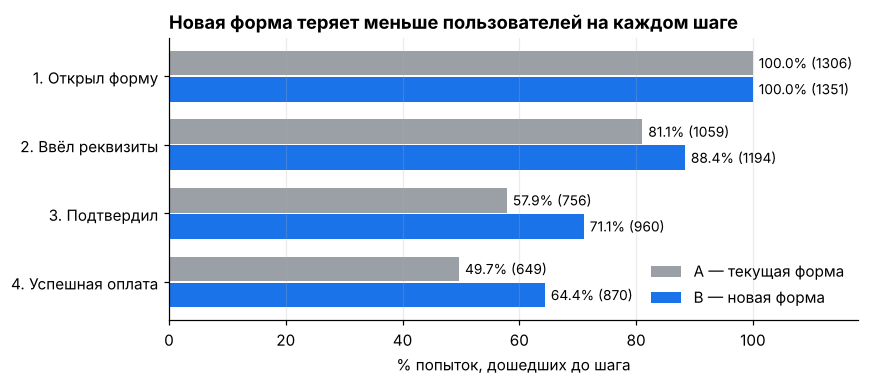

In [10]:
funnel = pay.groupby("group")[["r1", "r2", "r3", "r4"]].sum().T
funnel.index = STEP_NAMES
share = funnel / funnel.iloc[0] * 100
step_conv = (funnel / funnel.shift(1) * 100).iloc[1:]
display(pd.concat({"Попыток": funnel, "% от открытий": share.round(1),
                   "% от пред. шага": step_conv.round(1)}, axis=1))

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(4)
for k, g in enumerate("AB"):
    ax.barh(y + (k - .5) * .38, share[g], height=.36, color=COLOR[g], label=f"{g} — {'текущая' if g=='A' else 'новая'} форма")
    for yi, v, n in zip(y, share[g], funnel[g]):
        ax.text(v + 1, yi + (k - .5) * .38, f"{v:.1f}% ({n})", va="center", fontsize=9)
ax.set_yticks(y, STEP_NAMES); ax.invert_yaxis(); ax.set_xlim(0, 118)
ax.set_xlabel("% попыток, дошедших до шага"); ax.grid(axis="y", visible=False)
ax.set_title("Новая форма теряет меньше пользователей на каждом шаге", loc="left", fontweight="bold")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout(); fig.savefig(IMG / "funnel.png", bbox_inches="tight"); plt.show()

In [11]:
# Поведение: попытки на клиента и время шагов (защитные метрики)
att = per_user.groupby("group").n.agg(["mean", "max"]).round(2)
att["p (Манн-Уитни)"] = round(stats.mannwhitneyu(*[per_user.query("group==@g").n for g in "AB"]).pvalue, 3)
display(att.rename(columns={"mean": "попыток на клиента", "max": "максимум"}))
display(pd.crosstab(per_user.n, per_user.group).rename_axis("попыток у клиента"))

t = pay.assign(**{f"t{i}": (pay[b] - pay[a]).dt.total_seconds() / 60
                  for i, (a, b) in enumerate(zip(STEPS, STEPS[1:]), 1)})
display(t.groupby("group")[["t1", "t2", "t3"]].agg(["mean", "median"]).round(2)
        .rename(columns={"t1": "шаг 1→2", "t2": "шаг 2→3", "t3": "шаг 3→4"}))

,попыток на клиента,максимум,p (Манн-Уитни)
group,,,
A,1.74,4,0.143
B,1.80,4,0.143


group,A,B
попыток у клиента,,
1,388,353
2,204,237
3,122,116
4,36,44


шаг 1→2        шаг 2→3        шаг 3→4       
         mean median    mean median    mean median
group                                             
A        2.36    1.0    4.56    4.0    5.49    6.0
B        2.43    1.0    4.43    4.0    5.48    6.0

- У клиента 1–4 попытки, в среднем ≈1,8 — попытки одного клиента зависимы, это определяет выбор метода.
- Число попыток в группах не различается: новая форма не заставляет платить повторно.
- Время ввода реквизитов (шаг 1→2) не сократилось, медиана 1 мин в обеих группах. Скорее всего, время
  пишется с точностью до минуты, и ускорение в логах не видно — вопрос к логированию.

## 6. Выбор статистического метода

1. Метрика — доля, и напрашивается z-тест для долей. Но он требует независимых наблюдений.
2. Рандомизировали **клиентов**, а метрику считаем по **попыткам**; попытки одного клиента зависимы.
   Конверсия 1→4 = Σ успехов / Σ попыток по клиентам — **ratio-метрика**.
3. Основной метод — **дельта-метод**: дисперсия отношения через дисперсии и ковариацию числителя
   и знаменателя, посчитанные по клиентам.
4. Проверка — **бутстрап по клиентам** (10 000 повторов, клиенты пересэмплируются целиком).
5. Дополнительно — метрика на уровне клиента (доля клиентов с успешной оплатой, χ²): там наблюдения
   независимы.
6. Наивный z-тест по попыткам — только для сравнения.
7. Пошаговые конверсии — с поправкой Холма на 3 сравнения.

In [12]:
def delta_ratio(num, den):
    """Отношение sum(num)/sum(den) и его дисперсия дельта-методом (наблюдение = клиент)."""
    num, den = np.asarray(num, float), np.asarray(den, float)
    k, mx, my = len(num), den.mean(), num.mean()
    vx, vy, cxy = den.var(ddof=1), num.var(ddof=1), np.cov(num, den, ddof=1)[0, 1]
    var = (vy / mx**2 - 2 * my * cxy / mx**3 + my**2 * vx / mx**4) / k
    return my / mx, var

def compare(df, num="s", den="n", group="group"):
    """Разница B − A ratio-метрики, 95% ДИ и p-value (дельта-метод)."""
    a, b = df[df[group] == "A"], df[df[group] == "B"]
    ra, va = delta_ratio(a[num], a[den]); rb, vb = delta_ratio(b[num], b[den])
    d, se = rb - ra, np.sqrt(va + vb)
    return {"A, %": ra * 100, "B, %": rb * 100, "B − A, п.п.": d * 100,
            "ДИ низ": (d - 1.96 * se) * 100, "ДИ верх": (d + 1.96 * se) * 100,
            "отн. прирост, %": d / ra * 100, "p-value": 2 * stats.norm.sf(abs(d / se)),
            "клиентов A": len(a), "клиентов B": len(b), "se": se * 100}

## 7. Результаты

In [13]:
res = {}
res["Конверсия 1→4 (дельта-метод)"] = compare(per_user)

# Бутстрап по клиентам
B = 10_000
boot = []
for g in "AB":
    d = per_user[per_user.group == g][["s", "n"]].to_numpy()
    idx = rng.integers(0, len(d), (B, len(d)))
    boot.append(d[idx, 0].sum(1) / d[idx, 1].sum(1))
boot_diff = (boot[1] - boot[0]) * 100
lo, hi = np.percentile(boot_diff, [2.5, 97.5])
base = res["Конверсия 1→4 (дельта-метод)"]
res["Конверсия 1→4 (бутстрап)"] = {**base, "ДИ низ": lo, "ДИ верх": hi,
                                    "p-value": 2 * min((boot_diff <= 0).mean(), (boot_diff >= 0).mean())}

# Метрика клиента: доля клиентов с ≥1 успешной оплатой
pu = per_user.assign(paid=(per_user.s > 0).astype(int))
ga, gb = pu[pu.group == "A"].paid, pu[pu.group == "B"].paid
d = gb.mean() - ga.mean(); se = np.sqrt(ga.var() / len(ga) + gb.var() / len(gb))
res["Клиенты с ≥1 успешной оплатой (χ²)"] = {
    "A, %": ga.mean() * 100, "B, %": gb.mean() * 100, "B − A, п.п.": d * 100,
    "ДИ низ": (d - 1.96 * se) * 100, "ДИ верх": (d + 1.96 * se) * 100, "отн. прирост, %": d / ga.mean() * 100,
    "p-value": stats.chi2_contingency(pd.crosstab(pu.group, pu.paid), correction=False)[1],
    "клиентов A": len(ga), "клиентов B": len(gb)}

# Наивный z-тест по попыткам (для сравнения)
xa, xb = pay[pay.group == "A"].r4, pay[pay.group == "B"].r4
d = xb.mean() - xa.mean(); se_n = np.sqrt(xa.var() / len(xa) + xb.var() / len(xb))
pp = (xa.sum() + xb.sum()) / (len(xa) + len(xb))
z = d / np.sqrt(pp * (1 - pp) * (1 / len(xa) + 1 / len(xb)))
res["Наивный z-тест по попыткам"] = {
    "A, %": xa.mean() * 100, "B, %": xb.mean() * 100, "B − A, п.п.": d * 100,
    "ДИ низ": (d - 1.96 * se_n) * 100, "ДИ верх": (d + 1.96 * se_n) * 100, "отн. прирост, %": d / xa.mean() * 100,
    "p-value": 2 * stats.norm.sf(abs(z)), "клиентов A": len(xa), "клиентов B": len(xb)}

# Пошаговые конверсии, поправка Холма
pu_steps = pay.groupby(["user_id", "group"])[["r1", "r2", "r3", "r4"]].sum().reset_index()
step_res = {}
for i, name in enumerate(["Шаг 1→2", "Шаг 2→3", "Шаг 3→4"], 1):
    step_res[name] = compare(pu_steps[pu_steps[f"r{i}"] > 0], num=f"r{i+1}", den=f"r{i}")
pv = np.array([r["p-value"] for r in step_res.values()])
order = np.argsort(pv); holm = np.empty(3)
holm[order] = np.minimum(1, np.maximum.accumulate(pv[order] * (3 - np.arange(3))))
for (name, r), h in zip(step_res.items(), holm):
    res[f"{name} (Холм)"] = {**r, "p-value": h}

results = pd.DataFrame(res).T.drop(columns="se")
fmt_p = lambda v: "< 0.001" if v < 1e-3 else f"{v:.3f}"
display(results.round(2).astype({"клиентов A": int, "клиентов B": int})
        .assign(**{"p-value": results["p-value"].map(fmt_p)}))

se_main = base["se"]
mde = (stats.norm.ppf(.975) + stats.norm.ppf(.8)) * se_main
print(f"Дизайн-эффект (дисперсия дельта / наивная): {(se_main / (se_n * 100))**2:.2f}")
print(f"MDE при мощности 80% и α = 0,05: {mde:.1f} п.п.")

,"A, %","B, %","B − A, п.п.",ДИ низ,ДИ верх,"отн. прирост, %",p-value,клиентов A,клиентов B
Конверсия 1→4 (дельта-метод),49.69,64.40,14.70,10.99,18.41,29.59,< 0.001,750,750
Конверсия 1→4 (бутстрап),49.69,64.40,14.70,10.95,18.40,29.59,< 0.001,750,750
Клиенты с ≥1 успешной оплатой (χ²),65.47,80.40,14.93,10.50,19.37,22.81,< 0.001,750,750
Наивный z-тест по попыткам,49.69,64.40,14.70,10.98,18.43,29.59,< 0.001,1306,1351
Шаг 1→2 (Холм),81.09,88.38,7.29,4.49,10.09,8.99,< 0.001,750,750
Шаг 2→3 (Холм),71.39,80.40,9.01,5.58,12.45,12.63,< 0.001,670,707
Шаг 3→4 (Холм),85.85,90.62,4.78,1.67,7.88,5.57,0.003,546,644


Дизайн-эффект (дисперсия дельта / наивная): 0.99
MDE при мощности 80% и α = 0,05: 5.3 п.п.


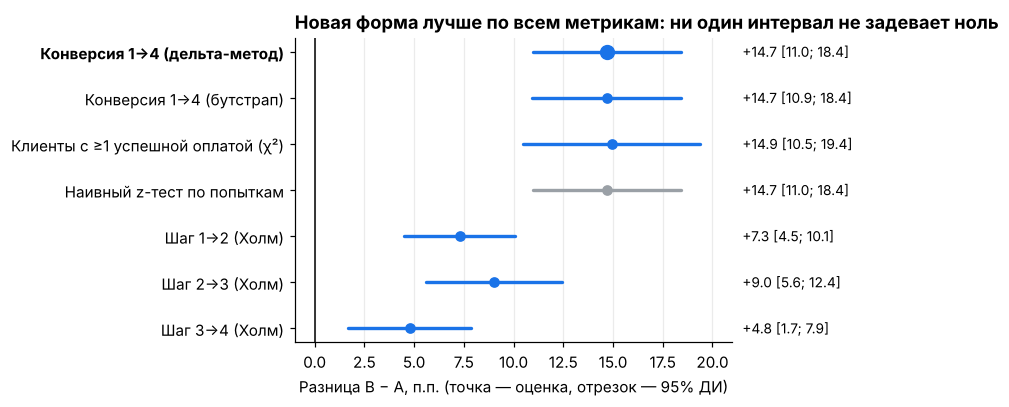

In [14]:
plot = results.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8))
yy = np.arange(len(plot))
main = plot.index.str.startswith("Конверсия 1→4 (дельта")
muted = plot.index.str.startswith("Наивный")
for yi, (name, r), m, mu in zip(yy, plot.iterrows(), main, muted):
    c = "#9AA0A6" if mu else COLOR["B"]
    ax.plot([r["ДИ низ"], r["ДИ верх"]], [yi, yi], color=c, lw=2.2, solid_capstyle="round")
    ax.plot(r["B − A, п.п."], yi, "o", color=c, ms=9 if m else 6)
    ax.text(21.5, yi, f"{r['B − A, п.п.']:+.1f} [{r['ДИ низ']:.1f}; {r['ДИ верх']:.1f}]", va="center", fontsize=9)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(yy, plot.index); ax.set_xlim(-1, 21); ax.grid(axis="y", visible=False)
ax.set_xlabel("Разница B − A, п.п. (точка — оценка, отрезок — 95% ДИ)")
ax.set_title("Новая форма лучше по всем метрикам: ни один интервал не задевает ноль", loc="left", fontweight="bold")
for lbl, m in zip(ax.get_yticklabels(), main):
    lbl.set_fontweight("bold" if m else "normal")
fig.tight_layout(); fig.savefig(IMG / "effects.png", bbox_inches="tight"); plt.show()

**Итог проверки гипотезы.** H₀ (конверсии равны) отвергается: конверсия 1→4 выросла на +14,7 п.п.
(95% ДИ 11,0…18,4, p < 0,001). Бутстрап, клиентская метрика и все три пошаговые конверсии
дают тот же вывод. Наивный z-тест почти совпадает с дельта-методом (дизайн-эффект ≈ 1): зависимость
попыток внутри клиента здесь слабая — но это результат проверки, а не допущение.

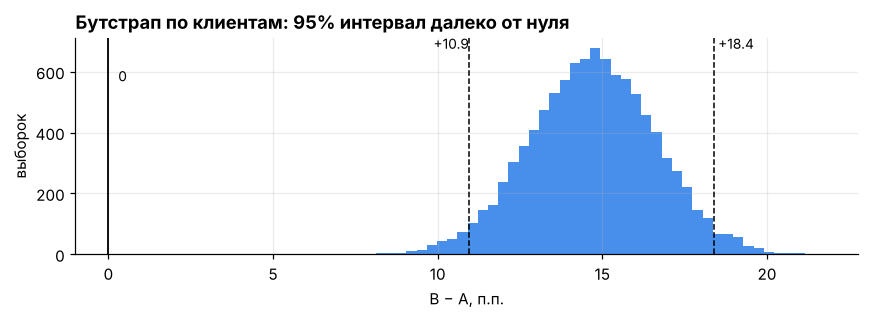

In [15]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(boot_diff, bins=50, color=COLOR["B"], alpha=.8)
for v in (lo, hi):
    ax.axvline(v, color="black", ls="--", lw=1)
    ax.text(v, ax.get_ylim()[1] * .95, f" {v:+.1f}", fontsize=9, ha="left" if v == hi else "right")
ax.axvline(0, color="black", lw=1.2); ax.text(0.3, ax.get_ylim()[1] * .8, "0", fontsize=9)
ax.set_xlim(-1, max(boot_diff) + 1)
ax.set_xlabel("B − A, п.п."); ax.set_ylabel("выборок")
ax.set_title("Бутстрап по клиентам: 95% интервал далеко от нуля", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(IMG / "bootstrap.png", bbox_inches="tight"); plt.show()

## 8. Устойчивость результата

### 8.1. Поправка на состав групп

Искажение от перекоса ≈ (перекос в составе групп) × (влияние признака на конверсию). Проверяем двумя
способами: пост-стратификация (разница внутри ячеек устройство × город, усреднённая с весами ячеек)
и регрессия с кластеризованной по клиентам ошибкой (устройство, город, возраст).

In [16]:
# Пост-стратификация: устройство × город
cells = []
for (dev, city), d in per_user.groupby(["device_type", "city"]):
    a, b = d[d.group == "A"], d[d.group == "B"]
    cells.append({"устройство": dev, "город": city, "клиентов": len(d),
                  "A, %": a.s.sum() / a.n.sum() * 100, "B, %": b.s.sum() / b.n.sum() * 100})
cells = pd.DataFrame(cells)
cells["вес"] = cells["клиентов"] / cells["клиентов"].sum()
cells["B − A, п.п."] = cells["B, %"] - cells["A, %"]
display(cells.round(2))
ps_effect = (cells["вес"] * cells["B − A, п.п."]).sum()
print(f"Эффект после пост-стратификации: {ps_effect:+.2f} п.п.")

# Регрессия на уровне попыток: успех ~ B + устройство + город + возраст, ошибки кластеризованы по клиенту
def ols_cluster(y, X, clusters):
    X = np.asarray(X, float); y = np.asarray(y, float)
    beta = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ beta
    XtXi = np.linalg.inv(X.T @ X)
    meat = sum(np.outer(X[ix].T @ e[ix], X[ix].T @ e[ix]) for ix in pd.Series(range(len(y))).groupby(clusters).indices.values())
    G, n, k = len(np.unique(clusters)), len(y), X.shape[1]
    V = XtXi @ meat @ XtXi * G / (G - 1) * (n - 1) / (n - k)
    return beta, np.sqrt(np.diag(V))

X = pd.get_dummies(pay[["device_type", "city"]], drop_first=True).astype(float)
X.insert(0, "B", (pay.group == "B").astype(float))
X["возраст (10 лет)"] = (pay.age - pay.age.mean()) / 10
X.insert(0, "const", 1.0)
beta, se_r = ols_cluster(pay.r4, X, pay.user_id.values)
reg = pd.DataFrame({"коэф., п.п.": beta * 100, "ДИ низ": (beta - 1.96 * se_r) * 100,
                    "ДИ верх": (beta + 1.96 * se_r) * 100,
                    "p-value": 2 * stats.norm.sf(np.abs(beta / se_r))}, index=X.columns).round(3)
display(reg)

,устройство,город,клиентов,"A, %","B, %",вес,"B − A, п.п."
0,android,Москва,314,43.87,63.38,0.21,19.50
1,android,Регион,251,50.00,61.58,0.17,11.58
2,android,СПб,210,53.33,67.28,0.14,13.95
3,ios,Москва,280,49.60,67.19,0.19,17.60
4,ios,Регион,262,51.66,61.34,0.17,9.69
5,ios,СПб,183,51.49,66.49,0.12,15.00


Эффект после пост-стратификации: +14.78 п.п.


,"коэф., п.п.",ДИ низ,ДИ верх,p-value
const,47.836,43.934,51.738,0.000
B,14.639,10.927,18.350,0.000
device_type_ios,1.583,-2.126,5.291,0.403
city_Регион,0.344,-4.038,4.726,0.878
city_СПб,3.851,-0.713,8.414,0.098
возраст (10 лет),-2.371,-4.642,-0.100,0.041


Устройство и город на конверсию значимо не влияют. Возраст влияет слабо (≈ −2,4 п.п. на каждые 10 лет),
но по возрасту группы сбалансированы (средний возраст 32,7 в обеих), поэтому искажать нечего: эффект
после поправки практически тот же. Поправка работает только для наблюдаемых признаков — вопрос к
механизму сплита остаётся.

### 8.2. Сегменты и неделя теста

In [17]:
seg_rows = []
for col, name in [("device_type", "Устройство"), ("city", "Город"), ("age_q", "Возраст")]:
    for v, d in per_user.groupby(col, observed=True):
        seg_rows.append({"срез": name, "сегмент": str(v), **compare(d)})
for w, d in pay.groupby("week", observed=True):
    du = d.groupby(["user_id", "group"]).agg(n=("r1", "size"), s=("r4", "sum")).reset_index()
    seg_rows.append({"срез": "Неделя (дни апреля)", "сегмент": str(w), **compare(du)})
seg = pd.DataFrame(seg_rows)

# Тест на неоднородность эффекта внутри каждого среза (Q Кокрена)
het = {}
for name, d in seg.groupby("срез", sort=False):
    w = 1 / d.se**2; pooled = (w * d["B − A, п.п."]).sum() / w.sum()
    Q = (w * (d["B − A, п.п."] - pooled) ** 2).sum()
    het[name] = stats.chi2.sf(Q, len(d) - 1)
display(seg.drop(columns="se").round(2).astype({"клиентов A": int, "клиентов B": int})
        .assign(**{"p-value": seg["p-value"].map(lambda v: "< 0.001" if v < 1e-3 else f"{v:.3f}")}))
display(pd.Series(het, name="p-value неоднородности").round(2).to_frame())

# Взаимодействие эффекта с непрерывным возрастом
Xi = X[["const", "B", "возраст (10 лет)"]].copy()
Xi["B × возраст"] = Xi["B"] * Xi["возраст (10 лет)"]
bi, si = ols_cluster(pay.r4, Xi, pay.user_id.values)
print(f"Изменение эффекта на каждые 10 лет возраста: {bi[3]*100:+.2f} п.п., p = {2*stats.norm.sf(abs(bi[3]/si[3])):.2f}")

,срез,сегмент,"A, %","B, %","B − A, п.п.",ДИ низ,ДИ верх,"отн. прирост, %",p-value,клиентов A,клиентов B
0,Устройство,android,48.81,63.81,15.01,9.92,20.09,30.74,< 0.001,406,369
1,Устройство,ios,50.76,64.96,14.20,8.77,19.64,27.98,< 0.001,344,381
2,Город,Москва,46.71,65.08,18.37,12.55,24.19,39.34,< 0.001,288,306
3,Город,Регион,50.76,61.45,10.69,4.12,17.26,21.06,0.001,268,245
4,Город,СПб,52.62,66.85,14.24,7.16,21.32,27.06,< 0.001,194,199
5,Возраст,≤27,52.86,68.63,15.78,8.87,22.68,29.85,< 0.001,202,211
6,Возраст,28–33,48.18,63.10,14.92,7.45,22.39,30.97,< 0.001,218,192
7,Возраст,34–38,49.82,61.15,11.33,3.18,19.49,22.75,0.006,157,162
8,Возраст,39+,47.83,63.87,16.05,8.79,23.31,33.55,< 0.001,173,185
9,Неделя (дни апреля),1–7,50.66,66.29,15.63,8.20,23.05,30.85,< 0.001,264,304


,p-value неоднородности
Устройство,0.83
Город,0.23
Возраст,0.83
Неделя (дни апреля),0.99


Изменение эффекта на каждые 10 лет возраста: -1.00 п.п., p = 0.67


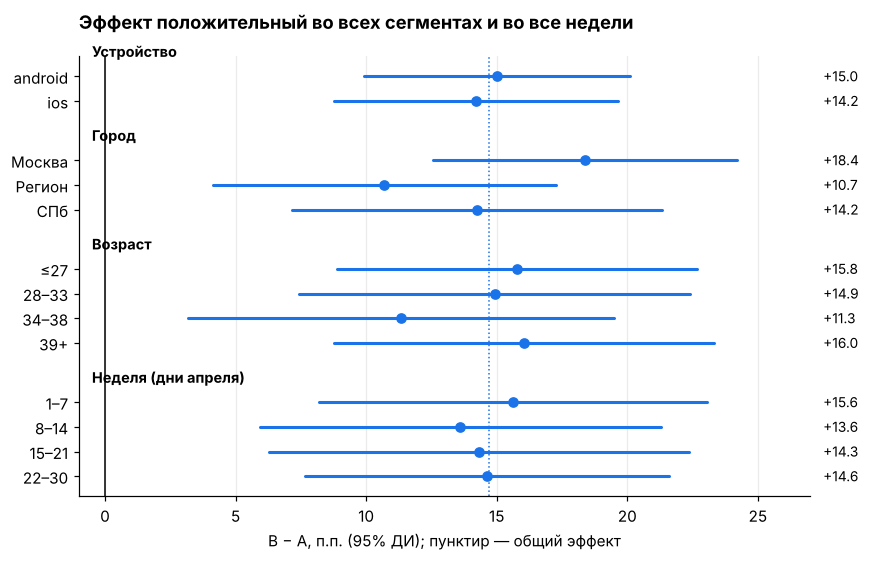

In [18]:
fig, ax = plt.subplots(figsize=(8, 5.2))
yy, labels, yv = 0, [], []
for name, d in seg.groupby("срез", sort=False):
    ax.text(-0.5, yy, name, fontweight="bold", va="center", fontsize=9.5)
    yy += 1
    for _, r in d.iterrows():
        ax.plot([r["ДИ низ"], r["ДИ верх"]], [yy, yy], color=COLOR["B"], lw=2, solid_capstyle="round")
        ax.plot(r["B − A, п.п."], yy, "o", color=COLOR["B"], ms=6)
        ax.text(27.5, yy, f"{r['B − A, п.п.']:+.1f}", va="center", fontsize=9)
        labels.append(r["сегмент"]); yv.append(yy); yy += 1
    yy += .4
ax.axvline(0, color="black", lw=1)
ax.axvline(base["B − A, п.п."], color=COLOR["B"], ls=":", lw=1)
ax.set_yticks(yv, labels); ax.invert_yaxis(); ax.set_xlim(-1, 27); ax.grid(axis="y", visible=False)
ax.set_xlabel("B − A, п.п. (95% ДИ); пунктир — общий эффект")
ax.set_title("Эффект положительный во всех сегментах и во все недели", loc="left", fontweight="bold", pad=18)
fig.tight_layout(); fig.savefig(IMG / "segments.png", bbox_inches="tight"); plt.show()

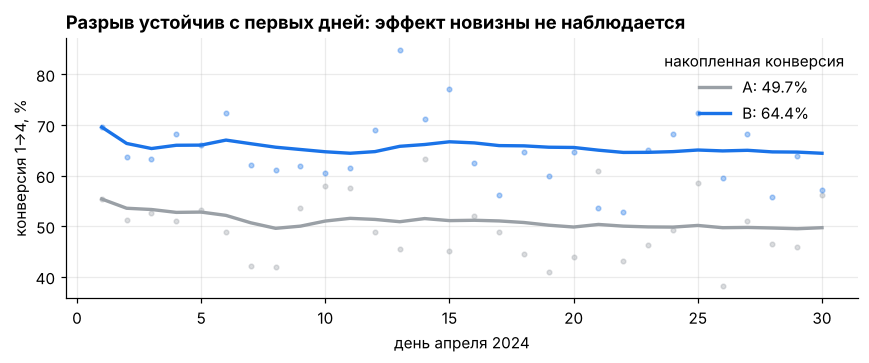

In [19]:
daily = pay.groupby(["day", "group"]).r4.agg(["sum", "size"]).unstack()
cum = daily.cumsum()
fig, ax = plt.subplots(figsize=(8, 3.4))
for g in "AB":
    ax.plot(daily.index, daily["sum"][g] / daily["size"][g] * 100, "o", color=COLOR[g], ms=3, alpha=.35)
    c = cum["sum"][g] / cum["size"][g] * 100
    ax.plot(c.index, c, color=COLOR[g], lw=2.2, label=f"{g}: {c.iloc[-1]:.1f}%")
ax.set_xlabel("день апреля 2024"); ax.set_ylabel("конверсия 1→4, %")
ax.set_title("Разрыв устойчив с первых дней: эффект новизны не наблюдается", loc="left", fontweight="bold")
ax.legend(frameon=False, title="накопленная конверсия")
fig.tight_layout(); fig.savefig(IMG / "cumulative.png", bbox_inches="tight"); plt.show()

### 8.3. Чувствительность к очистке данных

In [20]:
def effect_on(payments):
    """Основной эффект на произвольном наборе попыток (платёж без клиента = отдельный кластер)."""
    pt = payments.copy(); pt["s"] = pt.step4_success.notna().astype(int)
    pt["uid"] = pt.user_id.fillna(-pt.payment_id)
    agg = pt.groupby(["uid", "group"]).agg(n=("s", "size"), s=("s", "sum")).reset_index()
    r = compare(agg)
    return {k: r[k] for k in ["A, %", "B, %", "B − A, п.п.", "ДИ низ", "ДИ верх"]}

def variant(exclude, reassign_99002=False):
    t = pay_raw[~pay_raw.payment_id.isin(exclude)].copy()
    if reassign_99002:
        t.loc[t.payment_id == 99002, "group"] = "A"
    return effect_on(t)

sens = pd.DataFrame({
    "Базовая очистка":                         variant(drop_pays),
    "Без очистки":                             effect_on(pay_raw),
    "Вернуть клиента 9004 и платёж 7658":      variant([99001, 99002, 99003]),
    "Вернуть 99002 в группу клиента (A)":      variant([7658, 99001, 99003], reassign_99002=True),
    "Худший для B: спорные успехи — в A":      variant([99003], reassign_99002=True),
}).T.round(2)
display(sens)

# Сколько фиктивных успехов в A нужно, чтобы эффект стал незначимым
for k in range(0, 1000, 10):
    fake = pd.DataFrame({"user_id": -np.arange(1, k + 1), "group": "A", "n": 1, "s": 1})
    r = compare(pd.concat([per_user[["user_id", "group", "n", "s"]], fake]))
    if r["ДИ низ"] <= 0:
        print(f"Значимость пропадает при ≈{k} фиктивных успешных оплатах в группе A "
              f"(всего спорных записей — {len(drop_pays) + len(drop_users)})")
        break

,"A, %","B, %","B − A, п.п.",ДИ низ,ДИ верх
Базовая очистка,49.69,64.40,14.70,10.99,18.41
Без очистки,49.73,64.42,14.69,10.99,18.39
Вернуть клиента 9004 и платёж 7658,49.73,64.40,14.66,10.96,18.37
Вернуть 99002 в группу клиента (A),49.73,64.40,14.66,10.96,18.37
Худший для B: спорные успехи — в A,49.81,64.40,14.59,10.88,18.29


Значимость пропадает при ≈380 фиктивных успешных оплатах в группе A (всего спорных записей — 8)


## 9. Проверка расчёта на SQL

Тот же расчёт в SQL (SQLite из стандартной библиотеки Python). Запросы лежат в папке `sql/` и
переносятся в PostgreSQL / ClickHouse почти без изменений.

In [21]:
import sqlite3

con = sqlite3.connect(":memory:")
users_raw.to_sql("users", con, index=False)
pay_raw.assign(**{s: pay_raw[s].astype(str).replace("NaT", None) for s in STEPS}).to_sql("payments", con, index=False)

for f in ["01_clean.sql", "02_funnel.sql", "03_delta_method.sql"]:
    sql = (SQL_DIR / f).read_text(encoding="utf-8")
    if f == "01_clean.sql":
        con.executescript(sql)
    else:
        print(f"-- {f}"); display(pd.read_sql(sql, con))

r = pd.read_sql((SQL_DIR / "03_delta_method.sql").read_text(encoding="utf-8"), con).set_index("group")
d = r.loc["B", "conversion"] - r.loc["A", "conversion"]; se = np.sqrt(r.var_ratio.sum())
print(f"SQL: B − A = {d*100:+.2f} п.п. [{(d-1.96*se)*100:.2f}; {(d+1.96*se)*100:.2f}] — совпадает с Python")

-- 02_funnel.sql


,group,opened,entered,confirmed,success,conv_1_4_pct
0,A,1306,1059,756,649,49.69
1,B,1351,1194,960,870,64.40


-- 03_delta_method.sql


,group,users,conversion,var_ratio
0,A,750,0.496937,0.000186
1,B,750,0.643967,0.000172


SQL: B − A = +14.70 п.п. [10.99; 18.41] — совпадает с Python


## 10. Выводы и рекомендация

**Рекомендация: раскатывать новую форму на всех пользователей**, поэтапно.

- Конверсия 1→4: 49,7% → 64,4%, **+14,7 п.п.** (95% ДИ 11,0…18,4, p < 0,001),
  относительный прирост ≈30%. На каждую 1 000 открытий формы — примерно на 147 успешных оплат больше.
- Доля клиентов, оплативших хотя бы раз: 65,5% → 80,4%.
- Улучшение на каждом шаге: ввод реквизитов +7,3 п.п., подтверждение +9,0 п.п., успех после подтверждения
  +4,8 п.п. Это согласуется с механизмом: автозаполнение снимает ручной ввод и ошибки в реквизитах.
- Эффект устойчив: поправка на состав групп (+14,8 п.п.), все сегменты и недели положительны, решения по
  спорным записям оставляют эффект в пределах +14,6…+14,7 п.п.

**Условия раскатки и риски**
- Поэтапный запуск с защитными метриками, которых нет в выгрузке: платежи на неверные реквизиты,
  возвраты и отмены, обращения в поддержку. Главный риск автозаполнения — устаревшие реквизиты.
- Критерий отката: рост доли ошибочных платежей или обращений относительно контроля.

**Ограничения и что запросить у команды**
- Механизм сплита: группы назначены блоками ID — нужна гарантия, что это эквивалентно случайному
  назначению.
- Время шагов с точностью до минуты — эффект на скорость заполнения не измерить.
- Нет сумм платежей и кодов ошибок — нельзя оценить выручку и причину роста шага 3→4.